# Figure S2 — building the combined disorder scores used to train metapredict V3

Worked example for Chromogranin-A (UniProt P05059). AF2 pLDDT is rescaled to 0–1 (base 0.35, top 0.95) and inverted so high values mean disorder, then combined with metapredict V1 disorder: if either value exceeds 0.5 the larger is kept, otherwise the smaller; the result is Savitzky–Golay smoothed, clipped to [0, 1] and averaged over a 25-residue window. These "combined scores" (455,666 Swiss-Prot sequences) were the training targets for the V3 network, whose own prediction is shown last.

**How it is made.** pLDDT is read from `data/af2_plddt/P05059_af2_plddt.tsv` in the shared data directory (AlphaFold DB model AF-P05059-F1-model_v4). V1 and V3 scores are predicted live; the combined score uses `meta_predict_hybrid_v3` (in `hybrid_scores.py`, copied from the metapredict repository). The BRNN schematic in the published figure was drawn by hand.

**Outputs** (assembled into one panel): `figures/figure_S02_inputs.pdf` (pLDDT, rescaled pLDDT, V1 disorder), `figures/figure_S02_combined.pdf`, `figures/figure_S02_v3.pdf`

In [1]:
import matplotlib.pyplot as plt
import metapredict as meta
import numpy as np

from figtools import (V1_COLOR, V3_COLOR, apply_style, require_metapredict_3_1, save_panel,
                      shared_data_path)
from hybrid_scores import meta_predict_hybrid_v3

require_metapredict_3_1()
apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# pLDDT rescaling limits used to build the V3 training scores (Methods)
PLDDT_BASE = 0.35
PLDDT_TOP = 0.95
# score at which the combination rule switches between max and min
COMBINE_THRESHOLD = 0.5

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
plddt_table = np.genfromtxt(shared_data_path('af2_plddt', 'P05059_af2_plddt.tsv'), delimiter='\t', names=True, dtype=None, encoding=None)
p05059 = ''.join(plddt_table['amino_acid'])
plddt_p05059 = plddt_table['plddt'].astype(float)
residue = np.arange(1, len(p05059) + 1)

v1 = meta.predict_disorder(p05059, version='V1')

# normalise pLDDT to 0-1 and invert, so 1 = disordered and 0 = ordered
d = (plddt_p05059 / 100 - PLDDT_BASE) * (1 / (PLDDT_TOP - PLDDT_BASE))
d = 1 - d

# combined score (training target) and the V3 network's own prediction
combined = list(meta_predict_hybrid_v3({p05059: plddt_p05059 / 100}).values())[0]
v3 = meta.predict_disorder(p05059, version='V3')

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 790.33it/s]

Wrote figures/figure_S02_inputs.pdf


PosixPath('figures/figure_S02_inputs.pdf')

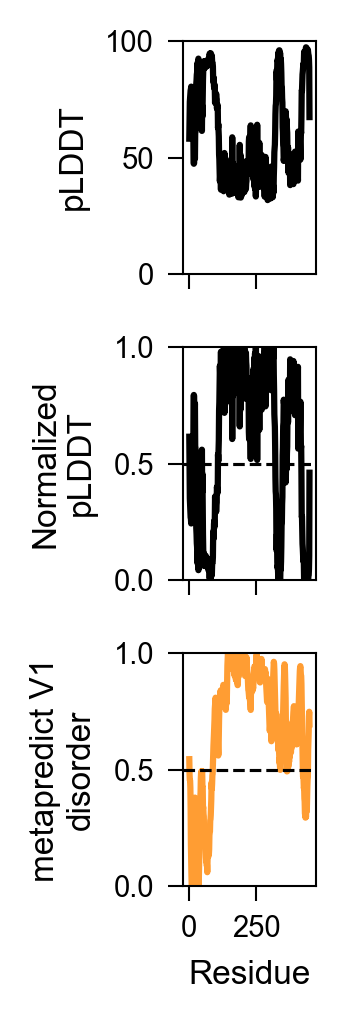

In [3]:
# inputs: raw pLDDT, rescaled/inverted pLDDT, V1 disorder
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, figsize=(1.3, 3.5), dpi=150, sharex=True)
ax1.plot(residue, plddt_p05059, color='black')
ax2.plot(residue, d, color='black')
ax3.plot(residue, v1, color=V1_COLOR)
for ax in (ax2, ax3):
    ax.axhline(COMBINE_THRESHOLD, linestyle='dashed', color='black', linewidth=0.75)
ax1.set_ylim([0, 100])
ax2.set_ylim([0, 1])
ax3.set_ylim([0, 1])
ax1.set_ylabel('pLDDT', fontsize=8)
ax2.set_ylabel('Normalized\npLDDT', fontsize=8)
ax3.set_ylabel('metapredict V1\ndisorder', fontsize=8)
ax3.set_xlabel('Residue', fontsize=8)
for ax in (ax1, ax2, ax3):
    ax.tick_params(labelsize=7)
plt.tight_layout()
save_panel(fig, 'figure_S02_inputs')

Wrote figures/figure_S02_combined.pdf
Wrote figures/figure_S02_v3.pdf


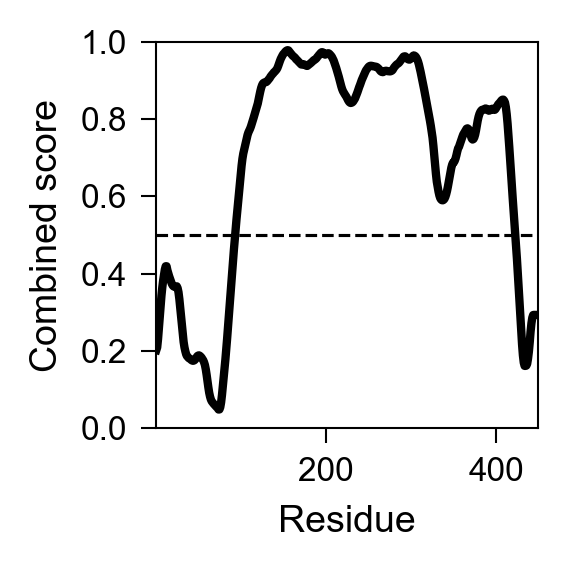

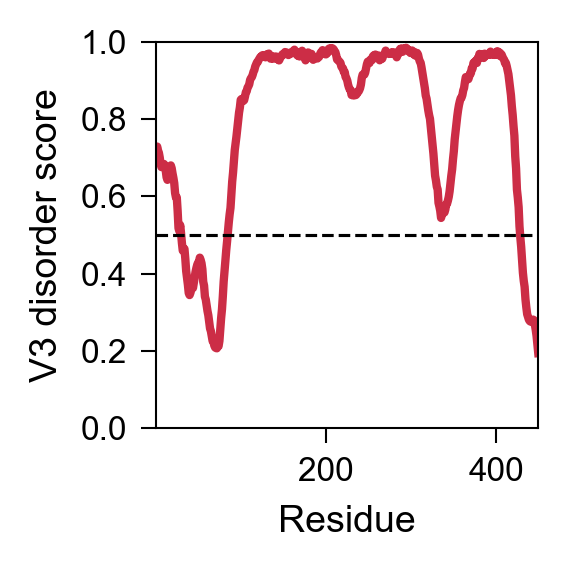

In [4]:
# combined score, then the V3 prediction trained to reproduce it
for scores, color, ylabel, name in [(combined, 'black', 'Combined score', 'figure_S02_combined'),
                                    (v3, V3_COLOR, 'V3 disorder score', 'figure_S02_v3')]:
    fig, ax = plt.subplots(figsize=(2, 2), dpi=150)
    ax.plot(residue, scores, color=color, linewidth=2)
    ax.axhline(COMBINE_THRESHOLD, linestyle='dashed', color='black', linewidth=0.75)
    ax.set_ylim([0, 1])
    ax.set_xlim([1, len(p05059)])
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_xlabel('Residue', fontsize=9)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    save_panel(fig, name)